# Mise à jour du classeur de la pharmacie

**À quoi sert ce notebook ?** Il remplit le classeur Excel `excel/Pharma_Analyse.xlsx` à partir du dernier export de ventes :
les données, les statistiques et la prévision du mois suivant. Le classeur reste un fichier Excel, parce que la pharmacienne
l'ouvre sans Python. Ce notebook, c'est la « machine » qui le met à jour.

**Mode d'emploi, à chaque nouvel export**
1. **Remplacer** les fichiers `data/Pharma_Ventes_Daily.csv` et `data/Pharma_Ventes_Hourly.csv` par les nouveaux, **avec exactement les mêmes noms**.
   Le nouvel export contient tout l'historique : on écrase l'ancien fichier, on n'en ajoute pas un deuxième.
2. **Fermer** le classeur s'il est ouvert dans Excel (sinon Python ne peut pas l'enregistrer).
3. Menu **Run → Run All Cells**.
4. Ouvrir `excel/Pharma_Analyse.xlsx` : tout est à jour.

**Le chemin suivi, en 10 étapes**

| Étape | Ce qu'elle fait |
|---|---|
| 0 | Préparer les outils et les réglages |
| 1 | Lire les ventes jour par jour |
| 2 | Additionner par mois, en gardant seulement les mois complets |
| 3 | Tester 4 méthodes de prévision sur les derniers mois |
| 4 | Prévoir le mois suivant |
| 5 | Remplacer l'onglet Données du classeur |
| 6 | Adapter les formules et les dates |
| 7 | Réécrire l'onglet Prévision |
| 8 | Mettre à jour la Synthèse |
| 9 | Recalculer l'onglet Statistiques |
| 9 bis | Regrouper par catégorie de médicament (et repérer les nouveaux) |
| 10 | Enregistrer et vérifier |

**Si une cellule affiche une erreur en rouge**, lis la **dernière ligne** du message : c'est elle qui dit le problème.
Chaque étape ci-dessous indique les erreurs les plus probables et quoi faire.

## Étape 0 : préparer les outils et les réglages

On charge les « boîtes à outils » Python, puis on écrit les réglages à un seul endroit.

**Pour modifier quelque chose** : c'est ici. Par exemple, pour tester sur 24 mois au lieu de 21, change `N_MOIS_TEST = 21` en `N_MOIS_TEST = 24`, puis Run All.

**Erreur possible** : `ModuleNotFoundError: No module named 'openpyxl'` (ou pandas, matplotlib) → l'outil n'est pas installé.
Dans le terminal : `python -m pip install -r requirements.txt`, puis Kernel → Restart, puis Run All.

In [1]:
import re                          # pour chercher et remplacer du texte (dans les formules Excel)
import warnings                    # pour cacher les avertissements sans importance
from copy import copy              # pour recopier la mise en forme d'une cellule Excel

import matplotlib.pyplot as plt    # pour dessiner les graphiques
import openpyxl                    # pour ouvrir, modifier et enregistrer le fichier Excel
import pandas as pd                # pour lire les CSV et faire les calculs
from openpyxl.styles import PatternFill   # pour colorier une cellule Excel

import categories as cat           # notre fichier categories.py : les catégories de médicaments

warnings.filterwarnings("ignore")  # on n'affiche pas les avertissements techniques
pd.set_option("display.width", 200)  # les tableaux s'affichent plus larges

# --- Réglages : c'est ici qu'on modifie si besoin ---
FICHIER_VENTES = "data/Pharma_Ventes_Daily.csv"     # export journalier (la référence)
FICHIER_HORAIRE = "data/Pharma_Ventes_Hourly.csv"   # export horaire (pour les ventes par heure)
FICHIER_CLASSEUR = "excel/Pharma_Analyse.xlsx"      # le classeur à mettre à jour
N_MOIS_TEST = 21      # nombre de mois sur lesquels on teste la prévision
GAIN_MINIMUM = 2      # points d'erreur en moins exigés pour dire « prévisible »

GROUPES = ["M01AB", "M01AE", "N02BA", "N02BE", "N05B", "N05C", "R03", "R06"]   # les 8 codes ATC
NOMS = {   # le nom courant de chaque groupe, tel qu'il apparaît dans le classeur
    "M01AB": "Anti-inflammatoires type diclofénac", "M01AE": "Anti-inflammatoires type ibuprofène",
    "N02BA": "Aspirine et dérivés", "N02BE": "Paracétamol", "N05B": "Anxiolytiques",
    "N05C": "Somnifères et sédatifs", "R03": "Asthme et BPCO", "R06": "Antihistaminiques (allergies)",
}
JOURS = ["Lundi", "Mardi", "Mercredi", "Jeudi", "Vendredi", "Samedi", "Dimanche"]
MOIS_FR = ["janvier", "février", "mars", "avril", "mai", "juin", "juillet",
           "août", "septembre", "octobre", "novembre", "décembre"]

def en_francais(date):
    # transforme une date en texte : 2019-10-01 devient « octobre 2019 »
    return f"{MOIS_FR[date.month - 1]} {date.year}"

def pourcent(x):
    # transforme un nombre en pourcentage à la française : 13.04 devient « 13,0 % »
    return f"{x:.1f} %".replace(".", ",")

print("Outils chargés, réglages prêts.")

Outils chargés, réglages prêts.


## Étape 1 : lire les ventes jour par jour

On lit l'export **journalier**. C'est notre référence : on a vérifié (avec `comparaison.py`) qu'il concorde à 100 % avec
l'horaire et l'hebdomadaire, alors que le mensuel est faux sur 31 mois sur 70.

**Ce que tu dois voir** : le nombre de jours et la période (2106 jours, du 02/01/2014 au 08/10/2019).

**Erreurs possibles**
- `FileNotFoundError` → le fichier n'est pas dans `data/`, ou n'a pas exactement le bon nom. Vérifie le nom, majuscules comprises.
- `ValueError: time data ... doesn't match format` → le nouvel export n'écrit plus les dates comme avant (mois/jour/année).
  Ouvre le CSV dans le Bloc-notes pour voir le nouveau format, puis adapte `format="%m/%d/%Y"`.

In [2]:
jour = pd.read_csv(FICHIER_VENTES)                                           # lit le fichier CSV
jour["datum"] = pd.to_datetime(jour["datum"], format="%m/%d/%Y")            # les dates sont au format américain : mois/jour/année
jour = jour.sort_values("datum").reset_index(drop=True)                      # range les jours dans l'ordre
premier_jour, dernier_jour = jour["datum"].min(), jour["datum"].max()        # première et dernière date de l'export
print(f"{len(jour)} jours, du {premier_jour:%d/%m/%Y} au {dernier_jour:%d/%m/%Y}")

2106 jours, du 02/01/2014 au 08/10/2019


## Étape 2 : additionner par mois, en gardant seulement les mois complets

On additionne les jours de chaque mois. **Pourquoi pas l'export mensuel ?** Parce qu'il ne correspond pas à la somme des jours
(par exemple octobre 2014 : 1 830 de paracétamol dans le mensuel, 1 046 en additionnant les jours).

Un mois est **complet** s'il contient tous ses jours. Janvier 2014 (l'export commence le 2) et octobre 2019 (il s'arrête le 8)
sont retirés : un mois à moitié rempli ferait croire à une chute des ventes.

**Ce que tu dois voir** : 68 mois complets, et le mois à prévoir (octobre 2019), puis un graphique.

In [3]:
mois = jour.set_index("datum")[GROUPES].resample("MS").sum()           # additionne les ventes de chaque mois
jours_par_mois = jour.set_index("datum").resample("MS").size()          # compte les jours présents dans chaque mois
mois = mois[jours_par_mois == jours_par_mois.index.days_in_month]       # garde seulement les mois qui ont tous leurs jours

dernier_mois = mois.index.max()                                          # le dernier mois complet
mois_cible = dernier_mois + pd.DateOffset(months=1)                      # le mois à prévoir = le suivant
print(f"{len(mois)} mois complets, de {en_francais(mois.index.min())} à {en_francais(dernier_mois)}")
print(f"Mois à prévoir : {en_francais(mois_cible)}")

68 mois complets, de février 2014 à septembre 2019
Mois à prévoir : octobre 2019


**Graphique 1 : le paracétamol mois par mois.** On voit tout de suite la saisonnalité : un pic chaque hiver, un creux chaque été.
C'est cette régularité qui rend la prévision possible.

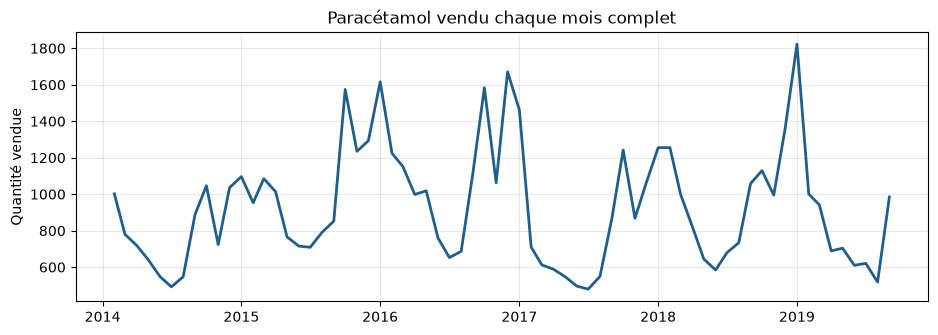

In [4]:
fig, ax = plt.subplots(figsize=(11, 3.5))                                # taille du graphique
ax.plot(mois.index, mois["N02BE"], color="#1F5F8B", linewidth=2)         # la courbe du paracétamol
ax.set_title("Paracétamol vendu chaque mois complet")                    # le titre
ax.set_ylabel("Quantité vendue")                                         # la légende de l'axe vertical
ax.grid(alpha=0.3)                                                       # un quadrillage léger
plt.show()                                                               # affiche le graphique

## Étape 3 : tester les 4 méthodes de prévision

**L'idée** : on fait comme si on était dans le passé. Avec les seules ventes connues jusqu'à décembre 2017, on prévoit
janvier 2018, puis on compare au vrai chiffre. On recommence chaque mois jusqu'au dernier mois complet : 21 prévisions testées.

**Pourquoi 21 mois ?** C'est tout ce qui va de janvier 2018 à septembre 2019. Avant, il faut garder assez d'historique
(2014-2017) pour que les méthodes aient de quoi apprendre, notamment l'effet de saison, qui a besoin de plusieurs années.

**Les 4 méthodes**
- 2 **naïves**, que n'importe qui ferait sans nous : le mois prochain = le mois dernier ; = le même mois l'an dernier.
- 2 **à nous** : la moyenne des 3 derniers mois ; le niveau des 12 derniers mois × l'effet de saison du mois.

**L'erreur** = l'écart entre la prévision et le vrai chiffre, en %. Exemple, paracétamol en septembre 2019 : réel 984,
notre méthode 971 (erreur 1,3 %), « mois dernier » 518 (erreur 47 %). On fait la moyenne de ces erreurs sur les 21 mois.

**Le verdict** : « Meilleure naïve » = la plus précise des 2 naïves ; « Notre meilleure » = la plus précise des 2 nôtres ;
« Gain » = la différence. Gain ≥ 2 points → **Oui** ; entre 0 et 2 → **Gain marginal** (mieux, mais trop peu pour être sûr) ; ≤ 0 → **Non**.

In [5]:
def naive_mois_dernier(historique, cible):
    return historique.iloc[-1]                                  # la dernière ligne connue = le mois dernier

def naive_annee_derniere(historique, cible):
    return historique.loc[cible - pd.DateOffset(years=1)]       # le même mois, un an avant

def moyenne_3_mois(historique, cible):
    return historique.iloc[-3:].mean()                          # la moyenne des 3 dernières lignes

def saison_et_niveau(historique, cible):
    niveau = historique.iloc[-12:].mean()                                        # niveau actuel = moyenne des 12 derniers mois
    indice = (historique / historique.rolling(12, center=True).mean()).dropna()  # chaque mois comparé à son année (1,2 = 20 % au-dessus)
    return niveau * indice[indice.index.month == cible.month].mean()             # niveau × effet moyen de ce mois-là

METHODES = {                                         # le nom affiché → la fonction qui calcule
    "Naïve : mois dernier": naive_mois_dernier,
    "Naïve : même mois an dernier": naive_annee_derniere,
    "Moyenne 3 derniers mois": moyenne_3_mois,
    "Saison x niveau": saison_et_niveau,
}
NAIVES = ["Naïve : mois dernier", "Naïve : même mois an dernier"]
MODELES = ["Moyenne 3 derniers mois", "Saison x niveau"]

mois_testes = mois.index[-N_MOIS_TEST:]              # les 21 derniers mois complets
lignes = []
for cible in mois_testes:                            # pour chaque mois testé...
    historique = mois[mois.index < cible]            # ...on ne garde que le passé (on « cache » la suite)
    for nom, methode in METHODES.items():            # ...chaque méthode fait sa prévision
        prevu = methode(historique, cible)
        for g in GROUPES:                            # ...et on note le prévu et le réel pour chaque groupe
            lignes.append({"methode": nom, "groupe": g, "reel": mois.loc[cible, g], "prevu": prevu[g]})
test = pd.DataFrame(lignes)
test["erreur %"] = (test["prevu"] - test["reel"]).abs() / test["reel"] * 100        # l'erreur de chaque prévision, en %

mape = test.pivot_table(index="groupe", columns="methode", values="erreur %", aggfunc="mean")[list(METHODES)].round(1)  # erreur moyenne

def conclure(gain):
    if gain >= GAIN_MINIMUM:
        return "Oui"
    if gain > 0:
        return "Gain marginal"
    return "Non"

verdict = pd.DataFrame({
    "Meilleure naïve": mape[NAIVES].min(axis=1),          # la plus petite erreur des 2 naïves
    "Notre meilleure": mape[MODELES].min(axis=1),         # la plus petite erreur de nos 2 méthodes
    "Modèle retenu": mape[MODELES].idxmin(axis=1),        # le nom de notre meilleure méthode
})
verdict["Gain"] = (verdict["Meilleure naïve"] - verdict["Notre meilleure"]).round(1)   # combien de points on gagne
verdict["Prévisible ?"] = verdict["Gain"].apply(conclure)                              # Oui / Gain marginal / Non

print(f"Test sur {len(mois_testes)} mois : de {en_francais(mois_testes[0])} à {en_francais(mois_testes[-1])}")
verdict

Test sur 21 mois : de janvier 2018 à septembre 2019


,Meilleure naïve,Notre meilleure,Modèle retenu,Gain,Prévisible ?
groupe,,,,,
M01AB,9.9,7.5,Saison x niveau,2.4,Oui
M01AE,12.5,12.7,Saison x niveau,-0.2,Non
N02BA,10.8,10.4,Moyenne 3 derniers mois,0.4,Gain marginal
N02BE,20.4,13.0,Saison x niveau,7.4,Oui
N05B,14.4,11.5,Moyenne 3 derniers mois,2.9,Oui
N05C,39.8,33.8,Moyenne 3 derniers mois,6.0,Oui
R03,27.9,30.0,Saison x niveau,-2.1,Non
R06,25.5,19.0,Saison x niveau,6.5,Oui


**Graphique 2 : notre erreur contre la meilleure naïve, groupe par groupe.** Plus la barre est basse, mieux c'est.
Quand la barre bleue foncée est nettement plus basse que la claire, le groupe est prévisible.

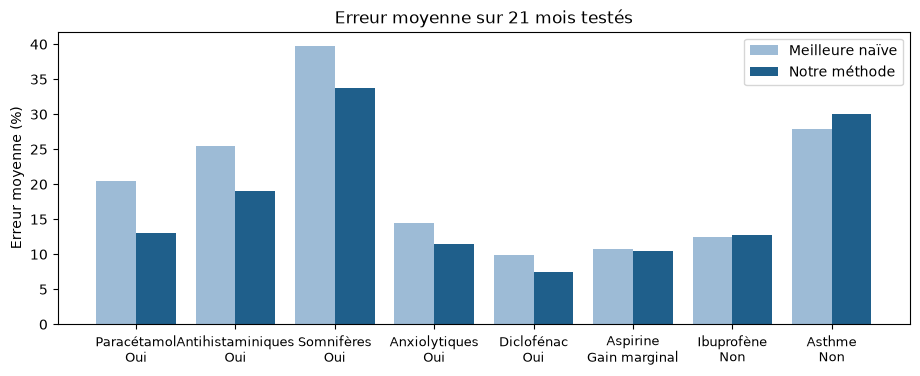

In [6]:
ordre = verdict.sort_values("Gain", ascending=False)                     # du plus gros gain au plus petit
x = range(len(ordre))
fig, ax = plt.subplots(figsize=(11, 3.8))
ax.bar([i - 0.2 for i in x], ordre["Meilleure naïve"], width=0.4, color="#9DBBD6", label="Meilleure naïve")
ax.bar([i + 0.2 for i in x], ordre["Notre meilleure"], width=0.4, color="#1F5F8B", label="Notre méthode")
ax.set_xticks(list(x))
COURTS = {"M01AB": "Diclofénac", "M01AE": "Ibuprofène", "N02BA": "Aspirine", "N02BE": "Paracétamol",
          "N05B": "Anxiolytiques", "N05C": "Somnifères", "R03": "Asthme", "R06": "Antihistaminiques"}   # noms courts pour le graphique
ax.set_xticklabels([f"{COURTS[g]}\n{ordre.loc[g, 'Prévisible ?']}" for g in ordre.index], fontsize=9)
ax.set_ylabel("Erreur moyenne (%)")
ax.set_title(f"Erreur moyenne sur {len(mois_testes)} mois testés")
ax.legend()
plt.show()

## Étape 4 : prévoir le mois suivant

Pour chaque groupe **prévisible**, on applique notre meilleure méthode à tout l'historique. Pour les autres, on écrit
« Pas fiable » : mieux vaut suivre le calendrier des saisons qu'un faux chiffre.

**Ce que tu dois voir** : le tableau des prévisions (paracétamol 1 307 pour octobre 2019), puis un graphique.

In [7]:
prevision = {}
for g in GROUPES:
    if verdict.loc[g, "Prévisible ?"] == "Oui":
        prevision[g] = round(METHODES[verdict.loc[g, "Modèle retenu"]](mois, mois_cible)[g])   # la méthode retenue, sur tout l'historique
    else:
        prevision[g] = "Pas fiable"

an_dernier = mois_cible - pd.DateOffset(years=1)          # le même mois l'an dernier, pour comparer
tableau_prevision = pd.DataFrame({
    f"Prévision {en_francais(mois_cible)}": prevision,
    f"Réel {en_francais(dernier_mois)}": mois.loc[dernier_mois].round(0),
    f"Réel {en_francais(an_dernier)}": mois.loc[an_dernier].round(0) if an_dernier in mois.index else None,
})
nb_oui = int((verdict["Prévisible ?"] == "Oui").sum())     # combien de groupes sont prévisibles
print(f"Prévisible pour {nb_oui} groupes sur 8")
tableau_prevision

Prévisible pour 5 groupes sur 8


,Prévision octobre 2019,Réel septembre 2019,Réel octobre 2018
M01AB,161,161.0,145.0
M01AE,Pas fiable,111.0,129.0
N02BA,Pas fiable,94.0,76.0
N02BE,1307,984.0,1129.0
N05B,238,228.0,287.0
N05C,21,16.0,25.0
R03,Pas fiable,121.0,327.0
R06,75,109.0,77.0


**Graphique 3 : la prévision du paracétamol.** Les 24 derniers mois réels, et le point orange = notre prévision du mois suivant.

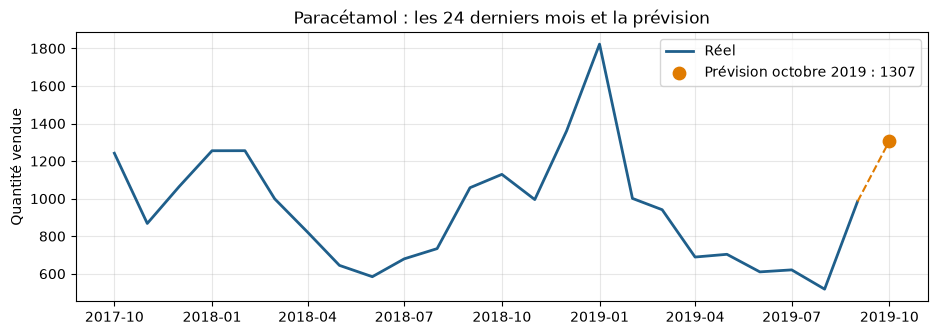

In [8]:
recents = mois["N02BE"].iloc[-24:]                                        # les 24 derniers mois réels
fig, ax = plt.subplots(figsize=(11, 3.5))
ax.plot(recents.index, recents, color="#1F5F8B", linewidth=2, label="Réel")
if prevision["N02BE"] != "Pas fiable":
    ax.plot([recents.index[-1], mois_cible], [recents.iloc[-1], prevision["N02BE"]], color="#E07B00", linestyle="--")
    ax.scatter([mois_cible], [prevision["N02BE"]], color="#E07B00", s=80, zorder=3,
               label=f"Prévision {en_francais(mois_cible)} : {prevision['N02BE']}")
ax.set_title("Paracétamol : les 24 derniers mois et la prévision")
ax.set_ylabel("Quantité vendue")
ax.grid(alpha=0.3)
ax.legend()
plt.show()

## Étape 5 : ouvrir le classeur et remplacer l'onglet Données

L'onglet Données contient une ligne par jour. Les formules de l'onglet Ventes (l'outil de la pharmacienne) vont y chercher les chiffres.
On efface les anciennes lignes, on écrit les nouvelles, en gardant la même mise en forme.

**Erreur possible** : `PermissionError: [Errno 13] Permission denied` → le classeur est ouvert dans Excel. Ferme-le, puis relance à partir de cette étape.

In [9]:
wb = openpyxl.load_workbook(FICHIER_CLASSEUR)        # ouvre le classeur Excel
donnees = wb["Données"]                              # va sur l'onglet Données
ancienne_derniere_ligne = donnees.max_row            # retient où s'arrêtaient les anciennes données

modele = [copy(c._style) for c in donnees[2]]        # copie la mise en forme de la 1re ligne de données
formats = [c.number_format for c in donnees[2]]      # et le format des nombres et des dates

donnees.delete_rows(2, ancienne_derniere_ligne)      # efface les anciennes lignes (on garde les titres en ligne 1)
for i, ligne in jour.iterrows():                     # pour chaque jour de l'export...
    valeurs = [ligne["datum"].to_pydatetime()] + [ligne[g] for g in GROUPES] + [
        ligne["datum"].year, ligne["datum"].month, JOURS[ligne["datum"].weekday()]]   # date, 8 groupes, année, mois, jour
    for j, valeur in enumerate(valeurs):             # ...on écrit chaque valeur dans sa colonne
        cellule = donnees.cell(row=i + 2, column=j + 1, value=valeur)
        cellule._style = copy(modele[j])
        cellule.number_format = formats[j]

derniere_ligne = len(jour) + 1                       # la nouvelle dernière ligne
print(f"Onglet Données : {len(jour)} jours écrits (lignes 2 à {derniere_ligne})")

Onglet Données : 2106 jours écrits (lignes 2 à 2107)


In [10]:
# --- Étape 4 bis : reprendre les onglets calculés par le script de Sofia (src/build_workbook.py) ---
import subprocess, sys                                                    # pour lancer un autre programme Python
from openpyxl.cell.cell import MergedCell                                 # pour reconnaître les cases fusionnées

subprocess.run([sys.executable, "src/build_workbook.py"], check=True,    # lance le script de Sofia :
               capture_output=True)                                       # il recrée output/Pharma_Analyse.xlsx
calcule = openpyxl.load_workbook("output/Pharma_Analyse.xlsx")           # ouvre le classeur qu'il vient de créer

ONGLETS_A_REPRENDRE = ["Synthèse", "Calendrier", "Conseils", "Questions", "Méthode", "État des données"]
LIGNES_GEREES_ICI = {"Synthèse": {25, 56}}             # lignes de la Synthèse que ce notebook écrit lui-même (prévision)

for nom in ONGLETS_A_REPRENDRE:
    source, cible = calcule[nom], wb[nom]
    if nom == "État des données":                      # cet onglet peut changer de taille : on vide d'abord ses valeurs
        for rangee in cible.iter_rows():
            for c in rangee:
                if not isinstance(c, MergedCell):
                    c.value = None
    for rangee in source.iter_rows():
        for c in rangee:
            if c.value is None or c.row in LIGNES_GEREES_ICI.get(nom, set()):
                continue                               # case vide, ou gérée plus bas : on n'y touche pas
            case = cible[c.coordinate]
            if isinstance(case, MergedCell):           # case fusionnée : seule la première case d'un bloc garde une valeur
                continue
            if not (isinstance(case.value, str) and case.value.startswith("=")):   # on ne remplace jamais une formule
                case.value = c.value

print("Onglets repris du script de Sofia :", ", ".join(ONGLETS_A_REPRENDRE))

Onglets repris du script de Sofia : Synthèse, Calendrier, Conseils, Questions, Méthode, État des données


## Étape 6 : adapter les formules et les dates du classeur

Les formules de l'onglet Ventes s'arrêtaient à l'ancienne dernière ligne (par exemple `$B$2107`). Si l'export a plus de jours,
on les fait aller jusqu'à la nouvelle. On met aussi à jour les dates écrites dans les textes (« Données disponibles du … au … »).

In [11]:
nb_formules = 0
for feuille in wb.worksheets:                        # dans chaque onglet...
    for rangee in feuille.iter_rows():
        for c in rangee:                             # ...chaque cellule
            if isinstance(c.value, str) and c.value.startswith("=") and f"${ancienne_derniere_ligne}" in c.value:
                c.value = re.sub(rf"\$(\w+)\${ancienne_derniere_ligne}\b", rf"$\g<1>${derniere_ligne}", c.value)  # remplace l'ancienne fin par la nouvelle
                nb_formules += 1

for nom in ["DateMin", "DateMax"]:                   # les plages nommées qui bornent les dates autorisées
    if nom in wb.defined_names:
        wb.defined_names[nom].attr_text = re.sub(rf"\${ancienne_derniere_ligne}\b", f"${derniere_ligne}",
                                                 wb.defined_names[nom].attr_text)

periode = f"du {premier_jour:%d/%m/%Y} au {dernier_jour:%d/%m/%Y}"
ventes = wb["Ventes"]
ventes["A2"] = re.sub(r"du \d\d/\d\d/\d{4} au \d\d/\d\d/\d{4}", periode, ventes["A2"].value)   # le texte d'aide
ventes["B5"] = (dernier_jour - pd.Timedelta(days=7)).to_pydatetime()      # date de début proposée : 7 jours avant la fin
ventes["B6"] = dernier_jour.to_pydatetime()                                # date de fin proposée : le dernier jour
wb["Questions"]["B14"] = f"{periode[0].upper()}{periode[1:]}. Une date en dehors est refusée."

print(f"{nb_formules} formules mises à jour, période : {periode}")

16 formules mises à jour, période : du 02/01/2014 au 08/10/2019


## Étape 7 : réécrire l'onglet Prévision

On recopie dans le classeur ce qu'on a calculé aux étapes 3 et 4 : la réponse, le tableau des erreurs, la prévision
et ses couleurs (vert = Oui, jaune = Gain marginal ou Pas fiable, rouge = Non).

**Erreur possible** : `KeyError: 'Prévision'` → l'onglet a été renommé dans Excel. Remets-lui exactement le nom « Prévision ».

In [12]:
prev = wb["Prévision"]
periode_test = f"{en_francais(mois_testes[0])} à {en_francais(mois_testes[-1])}"
non = [f"{NOMS[g]} ({g})" for g in GROUPES if verdict.loc[g, "Prévisible ?"] == "Non"]
marginal = [f"{NOMS[g]} ({g})" for g in GROUPES if verdict.loc[g, "Prévisible ?"] == "Gain marginal"]

reponse = f"{'Oui' if nb_oui else 'Non'}, pour {nb_oui} groupes sur 8"       # la phrase-réponse, construite à partir des résultats
if verdict.loc["N02BE", "Prévisible ?"] == "Oui":
    reponse += ", dont le paracétamol qui représente la moitié des ventes"
reponse += "."
if non:
    reponse += " Non pour : " + ", ".join(non) + "."
if marginal:
    reponse += " Gain trop faible pour : " + ", ".join(marginal) + "."

mois_avant = mois_testes[0] - pd.DateOffset(months=1)
prev["A2"] = (f"Question du manager : prévoir, pour chaque groupe, le mois qui suit le dernier mois complet "
              f"({en_francais(dernier_mois)}), donc {en_francais(mois_cible)}.")
prev["A6"] = reponse
prev["A9"] = (f"1. On fait comme si on était dans le passé : avec les seules ventes connues jusqu'à {en_francais(mois_avant)}, "
              f"on prévoit {en_francais(mois_testes[0])}, puis on compare au vrai chiffre. On répète chaque mois jusqu'à "
              f"{en_francais(mois_testes[-1])} : {len(mois_testes)} prévisions testées.")

for i, g in enumerate(GROUPES):                      # le tableau des erreurs (lignes 16 à 23)
    r = 16 + i
    for j, m in enumerate(METHODES):
        prev.cell(r, 3 + j).value = mape.loc[g, m] / 100
    prev.cell(r, 7).value = verdict.loc[g, "Meilleure naïve"] / 100
    prev.cell(r, 8).value = verdict.loc[g, "Notre meilleure"] / 100
    prev.cell(r, 9).value = verdict.loc[g, "Gain"]
    prev.cell(r, 10).value = verdict.loc[g, "Prévisible ?"]

couleurs = {"Oui": "FFC6EFCE", "Non": "FFFFC7CE", "Gain marginal": "FFFFEB9C"}   # vert, rouge, jaune
for i, g in enumerate(GROUPES):
    prev.cell(16 + i, 10).fill = PatternFill("solid", fgColor=couleurs[verdict.loc[g, "Prévisible ?"]])

prev["A25"] = f"PRÉVISION POUR {en_francais(mois_cible).upper()}"
prev["C26"] = f"Prévision {mois_cible:%m/%Y}"
prev["D26"] = f"Réel {dernier_mois:%m/%Y}"
prev["E26"] = f"Réel {an_dernier:%m/%Y}"
for i, g in enumerate(GROUPES):                      # le tableau de prévision (lignes 27 à 34)
    r = 27 + i
    c = prev.cell(r, 3)
    c.value = prevision[g]
    c.fill = PatternFill("solid", fgColor=couleurs["Oui" if prevision[g] != "Pas fiable" else "Gain marginal"])
    prev.cell(r, 4).value = int(round(mois.loc[dernier_mois, g]))
    prev.cell(r, 5).value = int(round(mois.loc[an_dernier, g])) if an_dernier in mois.index else None
    if prevision[g] != "Pas fiable":
        prev.cell(r, 6).value = (f"{verdict.loc[g, 'Modèle retenu']} (erreur moyenne "
                                 f"{verdict.loc[g, 'Notre meilleure']:.1f} % sur {len(mois_testes)} mois)")
    else:
        prev.cell(r, 6).value = "Aucune méthode ne bat la prévision naïve : se fier au calendrier des saisons"

prev["A36"] = (f"Mise à jour automatique par classeur.ipynb avec l'export du {dernier_jour:%d/%m/%Y}. "
               f"{en_francais(mois_cible).capitalize()} ne peut pas encore servir à vérifier la prévision : "
               f"il n'est pas terminé dans l'export.")
print(reponse)

Oui, pour 5 groupes sur 8, dont le paracétamol qui représente la moitié des ventes. Non pour : Anti-inflammatoires type ibuprofène (M01AE), Asthme et BPCO (R03). Gain trop faible pour : Aspirine et dérivés (N02BA).


## Étape 8 : mettre à jour les lignes « prévision » de l'onglet Synthèse

La page d'accueil du classeur reprend la réponse et les erreurs du paracétamol : on les remplace par les nouveaux chiffres.

In [13]:
synthese = wb["Synthèse"]
cible_court = f"{mois_cible:%m/%Y}"
para = verdict.loc["N02BE"]                          # les résultats du paracétamol
synthese["B25"] = (f"Peut-on prévoir les ventes du mois suivant ({cible_court}) ? Oui pour {nb_oui} groupes sur 8"
                   + (", dont le paracétamol (la moitié des ventes)." if para["Prévisible ?"] == "Oui" else "."))
synthese["C25"] = pourcent(para["Notre meilleure"])
synthese["D25"] = f"Erreur moyenne de notre prévision, paracétamol ({len(mois_testes)} mois testés)"
synthese["E25"] = pourcent(para["Meilleure naïve"])
synthese["G25"] = f"Oui : testé sur {len(mois_testes)} mois non utilisés pour construire la prévision"
synthese["B56"] = f"Peut-on prévoir le mois suivant ({cible_court}) ?"
synthese["C56"] = f"{'OUI' if nb_oui else 'NON'}, pour {nb_oui} groupes sur 8"
synthese["D56"] = f"Testé sur {len(mois_testes)} mois. Voir l'onglet Prévision."
synthese["C69"] = f"Peut-on prévoir le mois suivant ? Le test, et la prévision {cible_court}"
print("Synthèse mise à jour")

Synthèse mise à jour


## Étape 9 : recalculer l'onglet Statistiques

Les mêmes calculs que `statistiques.py`, écrits directement dans le classeur, en 7 tableaux : par groupe, indice saisonnier,
moyenne de chaque mois, jour de la semaine, heure, année, et chaque mois complet.

**Erreur possible** : `FileNotFoundError` sur `Pharma_Ventes_Hourly.csv` → l'export horaire manque dans `data/`.

In [14]:
stats = wb["Statistiques"]
style_titre, style_entete = copy(stats["A5"]._style), copy(stats["A6"]._style)          # on garde les styles de Sofia
style_premiere_col, style_valeur = copy(stats["A7"]._style), copy(stats["C7"]._style)
stats.delete_rows(5, stats.max_row)                  # on efface les anciens tableaux (on garde le titre en haut)

ventes_jour = jour.set_index("datum")[GROUPES]
horaire = pd.read_csv(FICHIER_HORAIRE)                                           # l'export horaire
horaire["datum"] = pd.to_datetime(horaire["datum"], format="%m/%d/%Y %H:%M")
par_heure = horaire.groupby(horaire["datum"].dt.hour)[GROUPES].mean().round(3)   # vente moyenne pour chaque heure
par_heure = par_heure[horaire.groupby(horaire["datum"].dt.hour)[GROUPES].sum().sum(axis=1) > 0]   # on enlève les heures fermées
mois_moyen = mois.groupby(mois.index.month).mean()                               # moyenne de chaque mois de l'année

tableaux = []   # chaque tableau = (titre, en-têtes, lignes)
tableaux.append(("PAR GROUPE (VENTES PAR JOUR, PUIS PAR MOIS COMPLET)",
    ["Groupe", "Nom", "Total", "Moyenne par jour", "Médiane par jour", "Écart-type par jour",
     "Coefficient de variation", "Maximum sur un jour", "Part des jours sans vente",
     "Moyenne par mois complet", "Mois le plus bas", "Mois le plus haut"],
    [[g, NOMS[g], round(ventes_jour[g].sum(), 1), round(ventes_jour[g].mean(), 2), round(ventes_jour[g].median(), 2),
      round(ventes_jour[g].std(), 2), round(ventes_jour[g].std() / ventes_jour[g].mean(), 2),
      round(ventes_jour[g].max(), 1), round((ventes_jour[g] == 0).mean(), 3),
      round(mois[g].mean(), 1), round(mois[g].min(), 1), round(mois[g].max(), 1)] for g in GROUPES]))
noms_mois = [m.capitalize() for m in MOIS_FR]
tableaux.append(("INDICE SAISONNIER (1 = MOIS MOYEN DU GROUPE)", ["Mois"] + GROUPES,
    [[noms_mois[m - 1]] + (mois_moyen.loc[m] / mois.mean()).round(2).tolist() for m in mois_moyen.index]))
tableaux.append(("VENTES MOYENNES DE CHAQUE MOIS DE L'ANNÉE", ["Mois"] + GROUPES,
    [[noms_mois[m - 1]] + mois_moyen.loc[m].round(1).tolist() for m in mois_moyen.index]))
semaine = ventes_jour.groupby(ventes_jour.index.weekday).mean().round(2)
tableaux.append(("VENTES MOYENNES PAR JOUR DE LA SEMAINE", ["Jour"] + GROUPES,
    [[JOURS[j]] + semaine.loc[j].tolist() for j in semaine.index]))
tableaux.append(("VENTES MOYENNES PAR HEURE", ["Heure"] + GROUPES,
    [[f"{h}h"] + par_heure.loc[h].tolist() for h in par_heure.index]))
annees = ventes_jour.groupby(ventes_jour.index.year)
tableaux.append(("VENTES MOYENNES PAR JOUR, ANNÉE PAR ANNÉE", ["Année", "Jours de données"] + GROUPES,
    [[a, int(annees.size()[a])] + annees.mean().round(2).loc[a].tolist() for a in annees.size().index]))
tableaux.append(("VENTES DE CHAQUE MOIS COMPLET, RECALCULÉES À PARTIR DES JOURS", ["Mois complet"] + GROUPES,
    [[f"{d:%Y-%m}"] + mois.loc[d].round(2).tolist() for d in mois.index]))

r = 5                                                # on écrit les tableaux les uns sous les autres, à partir de la ligne 5
for titre, entetes, lignes in tableaux:
    stats.cell(r, 1, titre)._style = copy(style_titre)
    stats.row_dimensions[r].height = 24
    r += 1
    for j, h in enumerate(entetes):
        stats.cell(r, j + 1, h)._style = copy(style_entete)
    stats.row_dimensions[r].height = 34.65 if len(entetes) > 10 else 20.25
    r += 1
    for ligne in lignes:
        for j, v in enumerate(ligne):
            v = v.item() if hasattr(v, "item") else v
            stats.cell(r, j + 1, v)._style = copy(style_premiere_col if j == 0 else style_valeur)
        stats.row_dimensions[r].height = 20.25
        r += 1
    r += 2                                           # deux lignes vides entre deux tableaux

print(f"Onglet Statistiques réécrit : {len(tableaux)} tableaux, {len(mois)} mois complets")

Onglet Statistiques réécrit : 7 tableaux, 68 mois complets


## Étape 9 bis : regrouper par catégorie de médicament

Chaque groupe de l'export a un **code ATC** (son « nom de référence »), qui se lit du plus large au plus précis :
`N02BE` = N (système nerveux) › N02 (analgésiques) › N02B (autres analgésiques) › N02BE (paracétamol).

On s'en sert pour ranger les médicaments en **catégories** : Douleur et inflammation, Anxiété et sommeil, Respiratoire, Allergies.
**Si un nouvel export contient un nouveau médicament** (une nouvelle colonne, par exemple `N02BB` ou `R05`), il est rangé tout seul
dans la bonne catégorie grâce au début de son code, et signalé comme **nouveau**. Les règles sont dans le fichier `categories.py`.

**Attention** : on additionne des quantités de médicaments différents. Ça sert à suivre une catégorie dans le temps, pas à comparer deux catégories.

Le résultat va dans un onglet **Catégories** du classeur (créé s'il n'existe pas).

In [15]:
codes = cat.codes_atc(jour.columns)                     # tous les codes ATC présents dans l'export (y compris les nouveaux)
nouveaux = cat.nouveaux_codes(jour.columns)             # ceux qui n'étaient pas dans l'export d'origine
par_categorie = cat.ventes_par_categorie(jour)          # ventes par mois complet et par catégorie
print(f"{len(codes)} médicaments, {par_categorie.shape[1]} catégories")
print("Nouveaux médicaments :", ", ".join(nouveaux) if nouveaux else "aucun")
cat.tableau_codes(jour.columns)

8 médicaments, 4 catégories
Nouveaux médicaments : aucun


,Code,Sous-groupe ATC,Catégorie,Nouveau ?
0,M01AB,Dérivés de l'acide acétique (diclofénac),Douleur et inflammation,Non
1,M01AE,Dérivés de l'acide propionique (ibuprofène),Douleur et inflammation,Non
2,N02BA,Acide salicylique et dérivés (aspirine),Douleur et inflammation,Non
3,N02BE,Anilides (paracétamol),Douleur et inflammation,Non
4,N05B,Anxiolytiques,Anxiété et sommeil,Non
5,N05C,Hypnotiques et sédatifs,Anxiété et sommeil,Non
6,R03,Médicaments de l'asthme et de la BPCO,Respiratoire,Non
7,R06,Antihistaminiques,Allergies,Non


**Graphique 4 : les ventes par catégorie, mois par mois.** Chaque catégorie a son propre rythme : la douleur et le respiratoire montent l'hiver, les allergies au printemps.

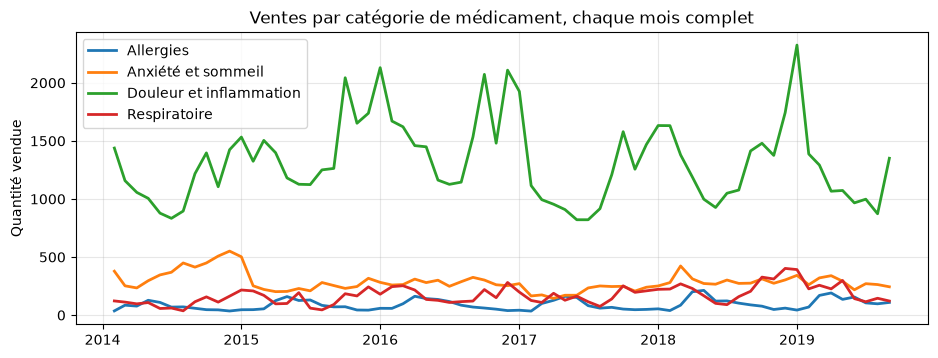

In [16]:
fig, ax = plt.subplots(figsize=(11, 3.8))
for nom in par_categorie.columns:
    ax.plot(par_categorie.index, par_categorie[nom], linewidth=2, label=nom)   # une courbe par catégorie
ax.set_title("Ventes par catégorie de médicament, chaque mois complet")
ax.set_ylabel("Quantité vendue")
ax.grid(alpha=0.3)
ax.legend()
plt.show()

In [17]:
# --- On écrit l'onglet Catégories dans le classeur ---
if "Catégories" not in wb.sheetnames:                                           # on le crée la première fois
    feuille_cat = wb.create_sheet("Catégories", index=wb.sheetnames.index("Statistiques") + 1)
    feuille_cat.sheet_properties.tabColor = stats.sheet_properties.tabColor
    feuille_cat.sheet_view.showGridLines = False
    for col, largeur in zip("ABCDEFGHI", [26, 44, 26, 16, 16, 16, 16, 16, 16]):
        feuille_cat.column_dimensions[col].width = largeur
feuille_cat = wb["Catégories"]
feuille_cat.delete_rows(1, feuille_cat.max_row + 1)                             # on repart d'une feuille vide

feuille_cat["A1"] = "Catégories de médicaments"
feuille_cat["A1"]._style = copy(stats["A1"]._style)
feuille_cat["A2"] = ("Groupes rangés par catégorie grâce à leur code ATC. Les quantités de médicaments différents sont additionnées : "
                     "à utiliser pour suivre une catégorie dans le temps, pas pour comparer deux catégories.")
feuille_cat["A2"]._style = copy(stats["A2"]._style)
feuille_cat["A3"] = "◀ Accueil"
feuille_cat["A3"]._style = copy(stats["A3"]._style)
feuille_cat["A3"].hyperlink = "#'Synthèse'!A1"

annees_cat = par_categorie.groupby(par_categorie.index.year).mean().round(1)    # moyenne par mois, année par année
douze = par_categorie.iloc[-12:].sum()                                          # les 12 derniers mois complets
douze_avant = par_categorie.iloc[-24:-12].sum()                                 # les 12 mois d'avant
tableaux_cat = [
    ("CORRESPONDANCE CODE ATC → CATÉGORIE", ["Code", "Sous-groupe ATC", "Catégorie", "Nouveau ?"],
     cat.tableau_codes(jour.columns).values.tolist()),
    ("VENTES MOYENNES PAR MOIS, PAR CATÉGORIE ET PAR ANNÉE", ["Année"] + list(par_categorie.columns),
     [[a] + annees_cat.loc[a].tolist() for a in annees_cat.index]),
    ("ÉVOLUTION SUR UN AN (12 DERNIERS MOIS COMPLETS CONTRE LES 12 PRÉCÉDENTS)",
     ["Catégorie", "12 derniers mois", "12 mois précédents", "Évolution"],
     [[c, round(douze[c], 1), round(douze_avant[c], 1),
       f"{(douze[c] / douze_avant[c] - 1) * 100:+.0f} %".replace(".", ",") if douze_avant[c] else "nouveau"]
      for c in par_categorie.columns]),
    ("NOUVEAUX MÉDICAMENTS DÉTECTÉS DANS CET EXPORT", ["Code", "Catégorie"],
     [[c, cat.categorie(c)] for c in nouveaux] or [["Aucun", "L'export contient les mêmes 8 groupes qu'au départ."]]),
]

r = 5
for titre, entetes, lignes in tableaux_cat:                     # même mise en forme que l'onglet Statistiques
    feuille_cat.cell(r, 1, titre)._style = copy(style_titre)
    r += 1
    for j, h in enumerate(entetes):
        feuille_cat.cell(r, j + 1, h)._style = copy(style_entete)
    r += 1
    for ligne in lignes:
        for j, v in enumerate(ligne):
            v = v.item() if hasattr(v, "item") else v
            feuille_cat.cell(r, j + 1, v)._style = copy(style_premiere_col if j == 0 else style_valeur)
        r += 1
    r += 2

print("Onglet Catégories écrit.")

Onglet Catégories écrit.


## Étape 10 : enregistrer et vérifier

On enregistre le classeur, puis on le rouvre pour vérifier ce qui est écrit dedans. Excel recalculera les formules à l'ouverture.

**Erreur possible** : `PermissionError` → le classeur est ouvert dans Excel : ferme-le et relance cette cellule.

In [18]:
wb.calculation.fullCalcOnLoad = True                 # demande à Excel de tout recalculer à l'ouverture
wb.save(FICHIER_CLASSEUR)                            # enregistre le classeur

verif = openpyxl.load_workbook(FICHIER_CLASSEUR)     # on le rouvre pour vérifier
print("Classeur enregistré :", FICHIER_CLASSEUR)
print("Onglets :", ", ".join(verif.sheetnames))
print("Dernière date dans Données :", verif["Données"].cell(verif["Données"].max_row, 1).value.strftime("%d/%m/%Y"))
print(verif["Prévision"]["A25"].value)
for r in range(27, 35):
    print(f"  {verif['Prévision'].cell(r, 1).value:<40} {verif['Prévision'].cell(r, 3).value}")
print()
if nouveaux:
    print()
    print("NOUVEAUX MÉDICAMENTS dans cet export :", ", ".join(nouveaux), "→ voir l'onglet Catégories.")

Classeur enregistré : excel/Pharma_Analyse.xlsx
Onglets : Synthèse, Ventes, Calendrier, Conseils, Prévision, Questions, Médicaments, Méthode, Statistiques, Catégories, État des données, Données
Dernière date dans Données : 08/10/2019
PRÉVISION POUR OCTOBRE 2019
  Anti-inflammatoires type diclofénac      161
  Anti-inflammatoires type ibuprofène      Pas fiable
  Aspirine et dérivés                      Pas fiable
  Paracétamol                              1307
  Anxiolytiques                            238
  Somnifères et sédatifs                   21
  Asthme et BPCO                           Pas fiable
  Antihistaminiques (allergies)            75



## En résumé

- Les données viennent de l'export **journalier**, vérifié contre les autres exports ; les mois incomplets sont retirés.
- La prévision est **testée honnêtement** : 21 fois, sans connaître la suite, contre la prévision la plus simple.
- Le classeur Excel est **à jour** : Données, outil Ventes, Statistiques, Prévision et Synthèse.
- Les médicaments sont **regroupés par catégorie** (onglet Catégories), et un **nouveau médicament** dans l'export est repéré tout seul.
- **À faire à la main** chaque mois : relire les textes de Calendrier, Conseils et État des données.

**Pour aller plus loin** : `analyse.ipynb` montre toute l'analyse (vérification des exports, saisonnalité, grippe) en détail.